# PyTorch Bilgisayarli Goru


`torchvision` kullanicagiz bu kutuphane biligisayarli gorude kullanilan ana kutupahendir

In [96]:
import torch
import torchvision

torch.__version__, torchvision.__version__

('2.8.0', '0.23.0')

## Veri setini indirelim

Kullanacagim dataset `torchvision.datasets` de kullandigimiz `FashionMNIST` veri seti torchvision datasette daha bircok veri seti bulunuyor

In [97]:
from torchvision.datasets import FashionMNIST

train_data = FashionMNIST(root='./data', # nereye konulacagi
                          train=True, # train olan kismi mi indirilecek die soruyor
                          download=True, # indirilsin mi
                          transform=torchvision.transforms.ToTensor()) # tensore cevirdik

test_data = FashionMNIST(root='./data',
                         train=False,
                         download=True,
                         transform=torchvision.transforms.ToTensor())


In [98]:
# Veri seti ne kadar
len(train_data), len(test_data)

(60000, 10000)

In [99]:
# Veri Setinin Siniflarina bakalim
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [100]:
# Veri setinin ilk ornegine bakalim

image, label=train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [101]:
image.shape

torch.Size([1, 28, 28])

### Veri Setini Gorsellestirelim

Text(0.5, 1.0, 'Ankle boot')

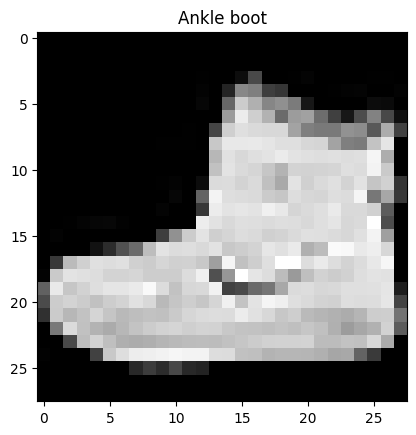

In [102]:
from matplotlib import pyplot as plt

plt.imshow(image.squeeze(), cmap='gray')
plt.title(class_names[label])

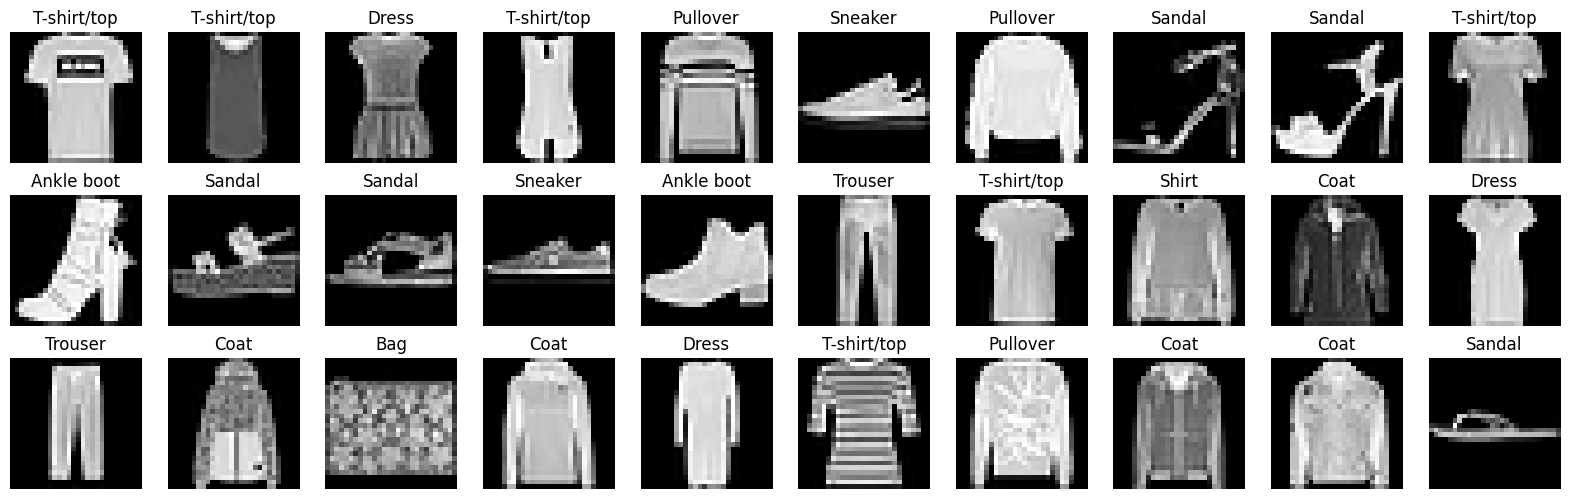

In [103]:
# Daha fazla Gorsel Gorelim
fig = plt.figure(figsize=(20, 6))
rows = 3
cols = 10
for i in range(1,31):
    img, label = train_data[i]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap='gray')
    plt.title(class_names[label])
    plt.axis(False)

## Veri Setini hazirlayalim
Suan bizim veri setimiz PyTorch veri seti seklinde

`DataLoader` veriyi PyTorch un izelyebilecegi sekle donusturucek

Daha aciklayici olarak, biz veri setimizi `mini batch` lere ayirmak istiyoruz




In [104]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataloader = DataLoader(train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True) # karistirmaya yariyor
test_dataloader = DataLoader(test_data,
                             batch_size=BATCH_SIZE,
                             shuffle=False)

print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Train dataloader buyuklugu: {len(train_dataloader)}, batch size: {BATCH_SIZE}")
print(f"Test dataloader buyuklugu: {len(test_dataloader)}, batch size: {BATCH_SIZE}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x15fabc650>, <torch.utils.data.dataloader.DataLoader object at 0x145e79610>)
Train dataloader buyuklugu: 1875, batch size: 32
Test dataloader buyuklugu: 313, batch size: 32


In [105]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))

## Linear model yapalim

In [106]:
from torch import nn
# flatten tanimliyorus
flatten_model = nn.Flatten()

# bir ornek alalim
x = train_features_batch[0]

#
output = flatten_model(x)

# Print out what happened
print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output.shape} -> [color_channels, height*width]")

Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) -> [color_channels, height*width]


In [107]:
class Model_0(torch.nn.Module):
    def __init__(self, input_size = 28*28, ara_katman = 10, output_size = 10):
        super(Model_0, self).__init__()
        self.first = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_size, out_features=ara_katman),
            nn.Linear(in_features=ara_katman, out_features=ara_katman),
            nn.Linear(in_features=ara_katman, out_features=output_size)
        )

    def forward(self, x):
        return self.first(x)

In [108]:
model_0 = Model_0()
model_0.state_dict()

OrderedDict([('first.1.weight',
              tensor([[ 0.0021,  0.0064, -0.0276,  ...,  0.0015, -0.0178,  0.0272],
                      [ 0.0336,  0.0072, -0.0230,  ...,  0.0331, -0.0034, -0.0114],
                      [-0.0022, -0.0301, -0.0318,  ..., -0.0219, -0.0016, -0.0188],
                      ...,
                      [-0.0018,  0.0334,  0.0310,  ..., -0.0127, -0.0065, -0.0184],
                      [-0.0103, -0.0274, -0.0253,  ..., -0.0082, -0.0055,  0.0048],
                      [ 0.0152, -0.0019, -0.0156,  ..., -0.0171,  0.0165, -0.0204]])),
             ('first.1.bias',
              tensor([ 0.0202,  0.0181,  0.0320, -0.0134, -0.0317,  0.0231, -0.0084, -0.0141,
                      -0.0169,  0.0332])),
             ('first.2.weight',
              tensor([[-0.2461,  0.0687,  0.0628, -0.1233,  0.1799,  0.1830,  0.2127,  0.0852,
                        0.0840,  0.0896],
                      [-0.1008, -0.2527,  0.0093,  0.0292,  0.1954,  0.0533,  0.0088, -0.1120,
   

### Loss ve Optimizer ayarlayalim

In [109]:
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_0.parameters(), lr=0.01)

In [110]:
from helper_functions import *

### Timer
Yapay zeka model egitimi biraz zaman alacagi icin timer ekleyelim

In [111]:
from timeit import default_timer as timer
def print_train_time(start: float,
                     end: float,
                     device: torch.device = None):
  """Prints difference between start and end time."""
  total_time = end - start
  print(f"Train time on {device}: {total_time:.3f} seconds")
  return total_time

In [112]:
start_time = timer()
# some code...
end_time = timer()
print_train_time(start=start_time, end=end_time, device="cpu")

Train time on cpu: 0.000 seconds


6.708999535476323e-06

### Modeli Egitelim

In [113]:
# proggres bar icin kutuphaneyi import ettim
from tqdm.auto import tqdm

torch.manual_seed(42)
train_time_start_on_cpu = timer()

# kac epouch olucagini yazdim
epochs = 10

for epoch in range(epochs):

  train_acc = 0
  train_loss = 0

  # proggres bari yaptim burada
  train_loop = tqdm(train_dataloader, leave=False, desc=f"Epoch {epoch} Training", mininterval = 0.5)

  # Döngü artık train_loop üzerinden ilerler.
  for X, y in train_loop:
    # batch değişkenine artık ihtiyaç yok (silindi)

    # model_0.train() model'in doğru moda alındığından emin olmak için döngüden önce de olabilir.
    model_0.train()

    # 1. Forward pass
    y_pred = model_0(X)


    loss = loss_fn(y_pred, y)
    train_loss += loss.item() # accumulate train loss için .item() kullanılması önerilir
    train_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

    optimizer.zero_grad()


    loss.backward()

    optimizer.step()



  train_loss /= len(train_dataloader)
  train_acc /= len(train_dataloader)

  ### Testing
  test_loss, test_acc = 0, 0
  model_0.eval()
  with torch.inference_mode():
    # Test döngüsü için de ilerleme çubuğu eklenmesi önerilir
    test_loop = tqdm(test_dataloader, leave=False, desc=f"Epoch {epoch} Testing")
    for X_test, y_test in test_loop:
      # 1. Forward pass
      test_pred = model_0(X_test)

      # 2. Calculate loss (accumulatively)
      test_loss += loss_fn(test_pred, y_test).item() # item() kullanıldı

      # 3. Calculate accuracy
      test_acc += accuracy_fn(y_true=y_test, y_pred=test_pred.argmax(dim=1))

    test_loss /= len(test_dataloader)

    test_acc /= len(test_dataloader)

    print(f"Epoch: {epoch} Train loss: {train_loss:.4f}, Test loss: {test_loss:.4f}, Train acc: {train_acc:.4f}, Test acc: {test_acc:.4f} ")

train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                            end=train_time_end_on_cpu,
                                            device=str(next(model_0.parameters()).device))

Epoch: 0 Train loss: 1.0802, Test loss: 0.6943, Train acc: 62.2517, Test acc: 75.2596 


Epoch: 1 Train loss: 0.6012, Test loss: 0.5787, Train acc: 78.9367, Test acc: 79.1633 


Epoch: 2 Train loss: 0.5268, Test loss: 0.5698, Train acc: 81.5650, Test acc: 78.6342 


Epoch: 3 Train loss: 0.4908, Test loss: 0.5073, Train acc: 82.7717, Test acc: 82.2784 


Epoch: 4 Train loss: 0.4698, Test loss: 0.4890, Train acc: 83.5717, Test acc: 82.7576 


Epoch: 5 Train loss: 0.4551, Test loss: 0.4895, Train acc: 84.1833, Test acc: 82.4381 


Epoch: 6 Train loss: 0.4463, Test loss: 0.4771, Train acc: 84.4350, Test acc: 83.2169 


Epoch: 7 Train loss: 0.4386, Test loss: 0.4728, Train acc: 84.7883, Test acc: 83.2069 


Epoch: 8 Train loss: 0.4329, Test loss: 0.4694, Train acc: 84.8617, Test acc: 83.4465 


Epoch: 9 Train loss: 0.4283, Test loss: 0.4749, Train acc: 85.2250, Test acc: 83.1270 
Train time on cpu: 13.241 seconds


In [114]:
# burada bir resim verdim ciktiyi istedim cikti da goruldugu uzere 9 olrak cikti 9 da ankle boot
y_pred=model_0(image)
cikti=torch.softmax(y_pred, dim=1).argmax(dim=1)
cikti

tensor([9])

In [115]:
torch.mps.is_available()

True

In [116]:
import torch
if torch.mps.is_available():
    device = "mps"
else:
    device = "cpu"

In [117]:
device

'mps'

## Non-Linear model yapalim

In [118]:
class Model_1(nn.Module):
    def __init__(self, input_size = 28*28, ara_katman = 10, output_size = 10):
        super().__init__()
        self.first = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_size, out_features=ara_katman),
            nn.ReLU(),
            nn.Linear(in_features=ara_katman, out_features=output_size)
        )


    def forward(self, x):
        return self.first(x)
torch.mps.manual_seed(42)
model_1 = Model_1().to(device)

next(model_1.parameters()).device

device(type='mps', index=0)

### Loss Function ve Accuracy yapalim


In [119]:
from helper_functions import accuracy_fn
loss_fn = torch.nn.CrossEntropyLoss() # multi class oldugu icin
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.01)


### Train ve Test icin birer fonksiyor yapalim
* Train icin `train_step()`
* Test icin `test_step()`


In [120]:
def train_step(model: torch.nn.Module,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device = device):

    train_acc = 0
    train_loss = 0
    model.train()

    # proggres bari yaptim burada
    train_loop = tqdm(train_dataloader, leave=False, desc=f"Epoch {epoch+1} Training", mininterval = 0.3)

  # Döngü artık train_loop üzerinden ilerler.
    for X_train, y_train in train_loop:
        # batch değişkenine artık ihtiyaç yok (silindi)
        X_train, y_train = X_train.to(device), y_train.to(device)
        # model_0.train() model'in doğru moda alındığından emin olmak için döngüden önce de olabilir.

        # 1. Forward pass
        y_pred = model(X_train)


        loss = loss_fn(y_pred, y_train)
        train_loss += loss.item() # accumulate train loss için .item() kullanılması önerilir
        train_acc += accuracy_fn(y_true=y_train, y_pred=y_pred.argmax(dim=1))

        optimizer.zero_grad()


        loss.backward()

        optimizer.step()



    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader)
    return train_loss, train_acc

In [121]:
def test_step(model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              accuracy_fn: torch.nn.Module,
              device: torch.device = device):
    test_loss, test_acc = 0, 0
    model.to(device)
    model.eval()
    with torch.inference_mode():

        test_loop = tqdm(test_dataloader, leave=False, desc=f"Epoch {epoch+1} Testing", mininterval = 0.1)

        for X_test, y_test in test_loop:
            X_test, y_test = X_test.to(device), y_test.to(device)
            test_pred = model(X_test)

            # 2. Calculate loss (accumulatively)
            test_loss += loss_fn(test_pred, y_test).item() # item() kullanıldı

            # 3. Calculate accuracy
            test_acc += accuracy_fn(y_true=y_test, y_pred=test_pred.argmax(dim=1))

        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)

    return test_loss, test_acc



In [122]:
epochs = 10
for epoch in range(epochs):
    train_loss, train_acc = train_step(model_1, loss_fn, optimizer, accuracy_fn, device)
    test_loss, train_acc = test_step(model_1, loss_fn, accuracy_fn, device)

    print(f"Epoch: {epoch+1} Train loss: {train_loss:.4f}, Test loss: {test_loss:.4f}, Train acc: {train_acc:.4f}, Test acc: {test_acc:.4f} ")


Epoch: 1 Train loss: 0.9879, Test loss: 0.6907, Train acc: 75.4892, Test acc: 83.1270 


Epoch: 2 Train loss: 0.5946, Test loss: 0.5634, Train acc: 80.9205, Test acc: 83.1270 


Epoch: 3 Train loss: 0.5206, Test loss: 0.5242, Train acc: 81.7192, Test acc: 83.1270 


Epoch: 4 Train loss: 0.4881, Test loss: 0.5017, Train acc: 82.3083, Test acc: 83.1270 


Epoch: 5 Train loss: 0.4693, Test loss: 0.4883, Train acc: 82.9373, Test acc: 83.1270 


Epoch: 6 Train loss: 0.4564, Test loss: 0.4807, Train acc: 83.1669, Test acc: 83.1270 


Epoch: 7 Train loss: 0.4465, Test loss: 0.4796, Train acc: 83.1370, Test acc: 83.1270 


Epoch: 8 Train loss: 0.4392, Test loss: 0.4694, Train acc: 83.5563, Test acc: 83.1270 


Epoch: 9 Train loss: 0.4331, Test loss: 0.4748, Train acc: 83.5164, Test acc: 83.1270 


Epoch: 10 Train loss: 0.4274, Test loss: 0.4595, Train acc: 83.8858, Test acc: 83.1270 


## CNN model yapalim

In [123]:
class Model_2(nn.Module):
    def __init__(self, input_size = 1, ara_katman = 10, output_size = 10):
        super().__init__()
        self.first_l = nn.Sequential(
            nn.Conv2d(in_channels=input_size, out_channels=ara_katman, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=ara_katman, out_channels=ara_katman, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.second_l = nn.Sequential(
            nn.Conv2d(in_channels=ara_katman, out_channels=ara_katman, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=ara_katman, out_channels=ara_katman, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.sinifladirici = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=ara_katman*7*7,
                      out_features=output_size),
        )

    def forward(self, x):
        x = self.first_l(x)
        #print(x.shape)
        x = self.second_l(x)
        #print(x.shape)
        x = self.sinifladirici(x)
        return x


model_2 = Model_2().to(device)



In [124]:
# Test etmek icin bir veri hazirlayalim
test_verisi = image.unsqueeze(dim=0)
pred = model_2(test_verisi.to(device))
pred

tensor([[-0.0363, -0.0468,  0.0340,  0.0590, -0.0015,  0.0009, -0.0096,  0.0406,
          0.0081, -0.0075]], device='mps:0', grad_fn=<LinearBackward0>)

### Loss Function ve Accuracy yapalim

In [125]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_2.parameters(), lr=0.01)

In [126]:
epochs = 10
for epoch in range(epochs):
    train_loss, train_acc = train_step(model_2, loss_fn, optimizer, accuracy_fn, device)
    test_loss, test_acc = test_step(model_2, loss_fn, accuracy_fn, device)
    print(f"Epoch: {epoch+1} Train loss: {train_loss:.4f}, Test loss: {test_loss:.4f}, Train acc: {train_acc:.4f}, Test acc: {test_acc:.4f} ")


Epoch: 1 Train loss: 1.1794, Test loss: 0.6487, Train acc: 56.8283, Test acc: 76.8371 


Epoch: 2 Train loss: 0.5700, Test loss: 0.4980, Train acc: 79.4517, Test acc: 82.3083 


Epoch: 3 Train loss: 0.4630, Test loss: 0.4468, Train acc: 83.3500, Test acc: 83.8359 


Epoch: 4 Train loss: 0.4113, Test loss: 0.4338, Train acc: 85.0750, Test acc: 84.0855 


Epoch: 5 Train loss: 0.3838, Test loss: 0.3970, Train acc: 86.2183, Test acc: 85.8327 


Epoch: 6 Train loss: 0.3626, Test loss: 0.4153, Train acc: 86.8883, Test acc: 84.6246 


Epoch: 7 Train loss: 0.3469, Test loss: 0.3677, Train acc: 87.5933, Test acc: 86.9209 


Epoch: 8 Train loss: 0.3339, Test loss: 0.3635, Train acc: 88.1100, Test acc: 86.5615 


Epoch: 9 Train loss: 0.3252, Test loss: 0.3571, Train acc: 88.2967, Test acc: 86.7412 


Epoch: 10 Train loss: 0.3158, Test loss: 0.3469, Train acc: 88.5783, Test acc: 87.6198 


## Karsilastirma yapalim

In [127]:
model_0_sonuc = test_step(model_0, loss_fn, accuracy_fn, device)
model_1_sonuc = test_step(model_1, loss_fn, accuracy_fn, device)
model_2_sonuc = test_step(model_2, loss_fn, accuracy_fn, device)

In [156]:
name = ["Model_0", "Model_1", "Model_2"]

In [159]:
import pandas as pd
df = pd.DataFrame([model_0_sonuc, model_1_sonuc, model_2_sonuc],columns=[ "Loss", "Accuracy"], index=name)
df.reset_index(inplace=True) # Index'i içeri alır
df.rename(columns={'index': 'Model Name'}, inplace=True) # Başlığı düzeltir
df

,Model Name,Loss,Accuracy
0,Model_0,0.474856,83.126997
1,Model_1,0.459466,83.885783
2,Model_2,0.346883,87.619808


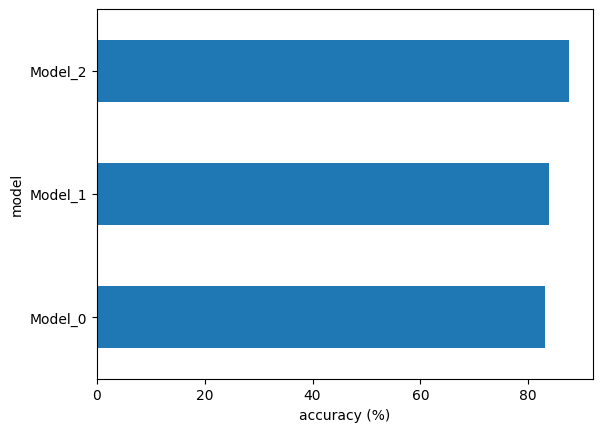

In [161]:
df.set_index("Model Name")["Accuracy"].plot(kind="barh")
plt.xlabel("accuracy (%)")
plt.ylabel("model");